# Vision — Statistik Dataset Gambar + Cari Gambar Kembar (deduplikasi hash)
**Kapan dipakai:** awal lomba, sebelum melatih apa pun. Menjawab: format file benar atau tidak
(`.jpg` yang isinya GIF/PNG?), mode warna (grayscale/RGBA?), ukuran seragam atau tidak, kelas
seimbang atau tidak, kelas mana yang gelap/berwarna aneh, dan **ada gambar kembar antara train
dan test?** (kebocoran: skor validasi terlalu bagus, skor leaderboard jelek).

**Bentuk data yang didukung** (pilih satu sel di bagian Baca data):
1. CSV `id,label` + gambar dalam satu folder (aktif)
2. folder per kelas: `train/<kelas>/*.jpg`
3. label tertulis di nama file: `Abyssinian_12.jpg` → `Abyssinian`

Ditambah folder lain yang ingin dicek kembarnya (misalnya gambar tanpa label) di `EXTRA_FOLDER`.

**Langkah:** baca tiap gambar → format, mode, ukuran, rasio, kecerahan, warna rata-rata →
ringkasan per kelas. Lalu `imagehash` phash → gambar dengan hash hampir sama = kembar.

**Data demo:** `pets` (10 ras kucing/anjing, Oxford-IIIT Pet). Dataset aslinya memang berisi
foto beruntun/kembar: ada gambar test yang sama persis dengan gambar train.

In [1]:
import glob
import os

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"              # tidak ada? pakai CSV contoh jawaban
TRAIN_IMAGE_FOLDER = f"{DATA_FOLDER}/train"
TEST_IMAGE_FOLDER = f"{DATA_FOLDER}/test"
EXTRA_FOLDER = f"{DATA_FOLDER}/tanpa_label"       # folder lain yang dicek, "" bila tidak ada
OUTPUT_FOLDER = "../../outputs/vision/statistik_dataset"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar
TARGET = "label"        # kolom kelas
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
MAX_HAMMING = 8         # jarak hash <= angka ini dianggap kembar (0 = sama persis, maks 64)

## Baca data — bentuk 1: CSV `id,label` + folder gambar (aktif)

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train["path"] = TRAIN_IMAGE_FOLDER + "/" + train[ID_COL].astype(str) + IMAGE_EXTENSION
test["path"] = TEST_IMAGE_FOLDER + "/" + test[ID_COL].astype(str) + IMAGE_EXTENSION
print("train:", train.shape, "| test:", test.shape)
print("contoh path:", train["path"].iloc[0])

train: (805, 4) | test: (269, 2)
contoh path: ../../data_latihan/vision/pets/train/Siamese_24.jpg


## (Alternatif) bentuk 2: folder per kelas `train/<kelas>/*.jpg`

In [4]:
# rows = []
# for class_name in sorted(os.listdir(TRAIN_IMAGE_FOLDER)):
#     for path in sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/{class_name}/*")):
#         rows.append([os.path.basename(path), class_name, path])
# train = pd.DataFrame(rows, columns=[ID_COL, TARGET, "path"])

## (Alternatif) bentuk 3: label di nama file `Abyssinian_12.jpg`

In [5]:
# train = pd.DataFrame()
# train["path"] = sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/*"))
# train[ID_COL] = train["path"].apply(os.path.basename)
# train[TARGET] = train[ID_COL].str.rsplit("_", n=1).str[0]

## Gabungkan semua gambar dalam satu tabel
Kolom `source` = asal gambar (train / test / extra). Test dan extra tidak berlabel.

In [6]:
extra = pd.DataFrame()
if EXTRA_FOLDER != "":
    extra["path"] = sorted(glob.glob(f"{EXTRA_FOLDER}/*"))
    extra[ID_COL] = extra["path"].apply(os.path.basename)
train["source"] = "train"
test["source"] = "test"
extra["source"] = "extra"
all_images = pd.concat([train, test, extra], ignore_index=True)
all_images["path"] = all_images["path"].str.replace("\\", "/")
all_images[TARGET] = all_images[TARGET].fillna("")
print(all_images["source"].value_counts())

source
train    805
extra    300
test     269
Name: count, dtype: int64


## Ukur tiap gambar
Satu baris per gambar. `format` = isi file sebenarnya (JPEG/PNG/GIF), bukan ekstensinya.
`mode` = RGB (warna), L (grayscale), RGBA (ada transparansi), P (palet, biasanya GIF).
Kecerahan dan warna diukur setelah `convert("RGB")`, jadi semua mode bisa dibandingkan.

In [7]:
rows = []
for path in all_images["path"]:
    original = Image.open(path)
    image = original.convert("RGB")
    pixels = np.asarray(image, dtype=float)
    rows.append({
        "format": original.format,
        "mode": original.mode,
        "width": image.width,
        "height": image.height,
        "ratio": image.width / image.height,
        "file_kb": os.path.getsize(path) / 1024,
        "brightness": pixels.mean(),
        "R": pixels[:, :, 0].mean(),
        "G": pixels[:, :, 1].mean(),
        "B": pixels[:, :, 2].mean(),
        "phash": str(imagehash.phash(image)),
    })
all_images = pd.concat([all_images, pd.DataFrame(rows)], axis=1)
train_stats = all_images[all_images["source"] == "train"].reset_index(drop=True)
print(all_images[["width", "height", "ratio", "file_kb", "brightness"]].describe().round(1))

        width  height   ratio  file_kb  brightness
count  1374.0  1374.0  1374.0   1374.0      1374.0
mean    436.1   390.3     1.2     99.9       112.7
std     166.7   148.3     0.3     71.1        32.4
min     133.0   112.0     0.5      4.7        15.7
25%     333.0   333.0     0.8     63.3        91.4
50%     500.0   375.0     1.3     99.5       112.1
75%     500.0   500.0     1.4    131.3       131.3
max    3264.0  2606.0     2.6   1098.8       230.2


## Format dan mode: ada yang aneh?
Ekstensi `.jpg` tapi format GIF/PNG → `cv2.imread` bisa gagal (GIF), PIL aman. Mode selain RGB
→ wajib `convert("RGB")` sebelum masuk model (grayscale = 1 kanal, RGBA = 4 kanal).

In [8]:
print(pd.crosstab(all_images["source"], all_images["format"]))
print(pd.crosstab(all_images["source"], all_images["mode"]))
extension = all_images["path"].str.rsplit(".", n=1).str[-1]
extension = extension.str.lower()
extension = extension.replace({"jpg": "JPEG", "jpeg": "JPEG", "png": "PNG", "gif": "GIF"})
mismatch = all_images[extension != all_images["format"]]
print("ekstensi tidak cocok dengan isi file:", len(mismatch))
mismatch[["source", ID_COL, "format", "mode"]]

format  GIF  JPEG  PNG
source                
extra     2   297    1
test      1   268    0
train     3   800    2
mode    L  P  RGB  RGBA
source                 
extra   2  2  295     1
test    1  1  267     0
train   0  3  800     2
ekstensi tidak cocok dengan isi file: 9


,source,id,format,mode
68,train,Egyptian_Mau_191.jpg,GIF,P
100,train,Egyptian_Mau_186.jpg,PNG,RGBA
122,train,Egyptian_Mau_167.jpg,GIF,P
126,train,Egyptian_Mau_177.jpg,GIF,P
572,train,Abyssinian_5.jpg,PNG,RGBA
1002,test,test_0198.jpg,GIF,P
1074,extra,Abyssinian_34.jpg,GIF,P
1130,extra,Egyptian_Mau_14.jpg,PNG,RGBA
1132,extra,Egyptian_Mau_145.jpg,GIF,P


## Ringkasan: ukuran, jumlah per kelas, warna rata-rata per kelas
Ukuran sangat beragam → perlu `ImageOps.fit` (potong) atau `ImageOps.pad` (beri tepi).

jumlah ukuran (lebar, tinggi) berbeda: 296
                            brightness      R      G      B  width  count
label                                                                    
Abyssinian                       108.2  124.4  107.4   92.8  441.3    149
Bengal                           120.4  131.8  122.7  106.6  411.4     53
Egyptian_Mau                      96.4   93.7   96.0   99.5  420.4     30
Persian                          114.8  129.2  114.7  100.6  442.5    105
Siamese                          121.1  130.7  122.3  110.3  433.4     82
beagle                           105.2  116.8  107.5   91.3  466.1    135
pug                              117.1  125.4  118.1  107.9  382.5    120
shiba_inu                        113.3  121.8  115.7  102.2  452.0     67
staffordshire_bull_terrier       121.1  129.6  126.0  107.5  468.5     23
yorkshire_terrier                112.8  125.3  117.2   96.0  403.9     41


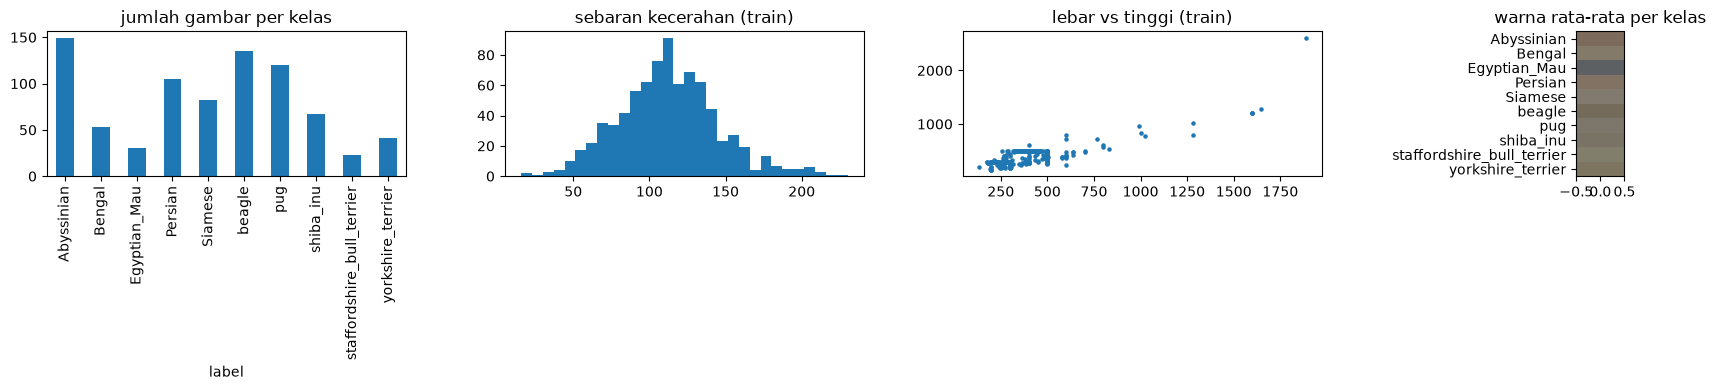

In [9]:
print("jumlah ukuran (lebar, tinggi) berbeda:", train_stats.groupby(["width", "height"]).ngroups)
summary = train_stats.groupby(TARGET)[["brightness", "R", "G", "B", "width"]].mean()
summary = summary.round(1)
summary["count"] = train_stats[TARGET].value_counts()
print(summary)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
summary["count"].plot.bar(ax=axes[0], title="jumlah gambar per kelas")
axes[1].hist(train_stats["brightness"], bins=30)
axes[1].set_title("sebaran kecerahan (train)")
axes[2].scatter(train_stats["width"], train_stats["height"], s=5)
axes[2].set_title("lebar vs tinggi (train)")
colors = summary[["R", "G", "B"]].to_numpy() / 255
axes[3].imshow(colors.reshape(len(summary), 1, 3), aspect=0.3)
axes[3].set_yticks(range(len(summary)), list(summary.index))
axes[3].set_title("warna rata-rata per kelas")
plt.tight_layout()
plt.savefig(f"{OUTPUT_FOLDER}/statistik.png", dpi=110)
plt.show()

## Cari kembar: tiap gambar test/extra dibandingkan dengan semua gambar train
Hash teks diubah jadi 64 bit. Jarak Hamming = jumlah bit berbeda. Kembar sama persis saja:
`all_images["phash"].duplicated(keep=False).sum()`.

In [10]:
def hash_bits(hash_texts):
    bits = []
    for text in hash_texts:
        bits.append(imagehash.hex_to_hash(text).hash.flatten())
    return np.array(bits)


train_bits = hash_bits(train_stats["phash"])
others = all_images[all_images["source"] != "train"].reset_index(drop=True)
other_bits = hash_bits(others["phash"])
twins = []
for row in range(len(others)):
    distances = (train_bits != other_bits[row]).sum(axis=1)    # jarak ke semua gambar train
    nearest = distances.argmin()
    if distances[nearest] <= MAX_HAMMING:
        twins.append({"source": others["source"][row], "other": others["path"][row],
                      "train": train_stats["path"][nearest], "distance": distances[nearest],
                      "train_label": train_stats[TARGET][nearest]})
twins = pd.DataFrame(twins, columns=["source", "other", "train", "distance", "train_label"])
print("gambar yang punya kembar di train:", len(twins), "dari", len(others))
twins.to_csv(f"{OUTPUT_FOLDER}/kembar_dengan_train.csv", index=False)
twins.sort_values("distance")

gambar yang punya kembar di train: 4 dari 569


,source,other,train,distance,train_label
1,test,../../data_latihan/vision/pets/test/test_0225.jpg,../../data_latihan/vision/pets/train/Abyssinia...,0,Abyssinian
0,test,../../data_latihan/vision/pets/test/test_0195.jpg,../../data_latihan/vision/pets/train/Abyssinia...,8,Abyssinian
2,extra,../../data_latihan/vision/pets/tanpa_label/shi...,../../data_latihan/vision/pets/train/shiba_inu...,8,shiba_inu
3,extra,../../data_latihan/vision/pets/tanpa_label/sta...,../../data_latihan/vision/pets/train/staffords...,8,staffordshire_bull_terrier


## Kembar di dalam train, dan kembar yang labelnya beda (label berisik?)
Kembar di dalam train membuat validasi acak terlalu optimis (satu di latih, kembarannya di
validasi). Solusi: kelompokkan kembar lalu pakai `GroupKFold`.

In [11]:
same_class = 0
different_class = 0
for row in range(len(train_stats)):
    distances = (train_bits[row + 1:] != train_bits[row]).sum(axis=1)
    for other_row in np.where(distances <= MAX_HAMMING)[0] + row + 1:
        if train_stats[TARGET][row] == train_stats[TARGET][other_row]:
            same_class += 1
        else:
            different_class += 1
            print("label beda:", train_stats[ID_COL][row], "↔", train_stats[ID_COL][other_row])
print("pasangan kembar di train | label sama:", same_class, "| label beda:", different_class)

pasangan kembar di train | label sama: 5 | label beda: 0


## Contoh pasangan kembar (atas: test/extra, bawah: train)

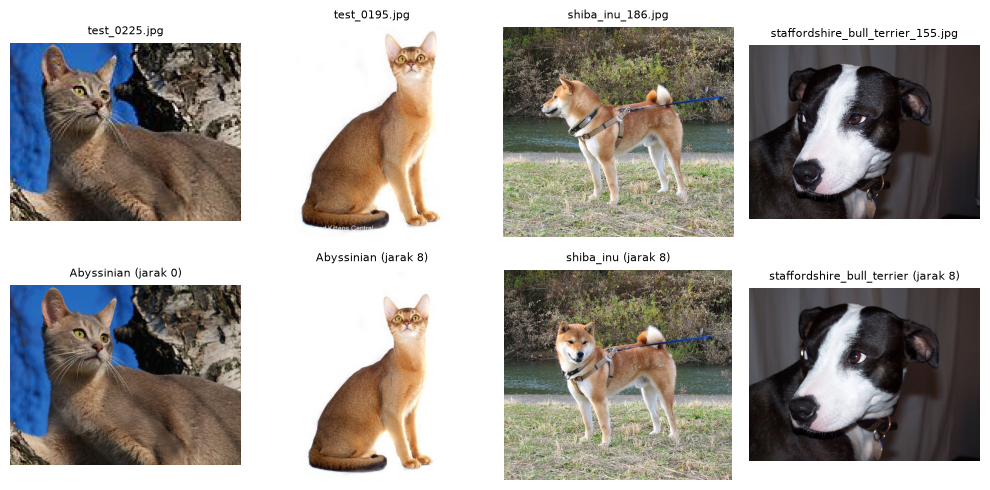

In [12]:
examples = twins.sort_values("distance").head(6)
examples = examples.reset_index(drop=True)
fig, axes = plt.subplots(2, max(len(examples), 1), figsize=(2.5 * max(len(examples), 1), 5),
                         squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for column in range(len(examples)):
    axes[0, column].imshow(Image.open(examples["other"][column]).convert("RGB"))
    axes[0, column].set_title(os.path.basename(examples["other"][column]), fontsize=8)
    axes[1, column].imshow(Image.open(examples["train"][column]).convert("RGB"))
    title = f"{examples['train_label'][column]} (jarak {examples['distance'][column]})"
    axes[1, column].set_title(title, fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_FOLDER}/kembar_contoh.png", dpi=110)
plt.show()

## Simpan tabel statistik semua gambar (untuk notebook lain / laporan)

In [13]:
all_images.to_csv(f"{OUTPUT_FOLDER}/statistik_semua_gambar.csv", index=False)
print(all_images.shape)

(1374, 16)


## Cara membaca hasil → tindakan
- **Gambar test kembar dengan train:** labelnya hampir pasti sama dengan label train kembarannya.
  Boleh dipakai bila aturan lomba mengizinkan (tanyakan panitia); minimal sebutkan di laporan.
- **Kembar di dalam train:** validasi acak terlalu optimis → `GroupKFold` dengan grup kembar.
- **Kembar dengan label beda:** label berisik; lihat `label_berisik`.
- **Format/mode campur:** selalu `Image.open(path).convert("RGB")`.
- **`MAX_HAMMING` terlalu besar** (≥ 10) → gambar berbeda ikut dianggap kembar. Selalu lihat
  grid contoh sebelum percaya angkanya.